# 02. Сравнение моделей

Цель: выяснить, какая модель лучше всего предсказывает зарплату, и **откуда берётся качество**:
из сложности модели или из новых признаков (текста объявления).

## Модели

| Модель | Что это | Признаки |
|---|---|---|
| Медиана профессии | базовая линия из ноутбука 01 | профессия |
| Ridge | линейная модель с регуляризацией | структурированные |
| Random Forest | среднее многих деревьев решений, обученных на случайных подвыборках | структурированные |
| LightGBM | градиентный бустинг: деревья строятся по очереди, каждое исправляет ошибки предыдущих | структурированные |
| CatBoost | градиентный бустинг со встроенной обработкой категорий | структурированные |
| Ridge + TF-IDF | Ridge + слова и пары слов из названия и требований | структурированные + текст |
| CatBoost + текст | CatBoost со встроенной обработкой текста | структурированные + текст |

## Как сравниваются модели

1. **5-кратная кросс-валидация на обучающей выборке** с группировкой одинаковых объявлений:
   каждая модель обучается 5 раз на 4/5 данных и проверяется на оставшейся 1/5.
   Это даёт среднюю ошибку и её разброс, то есть показывает, насколько разница между
   моделями устойчива.
2. **Финальная проверка на тестовой выборке**, которая не использовалась при выборе.

Гиперпараметры здесь взяты разумными по умолчанию; подбор (Optuna) будет следующим шагом.

In [1]:
import sys, time, warnings
sys.path.insert(0, "../src")
import prep

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
import lightgbm as lgb
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"

df = prep.load()
data = prep.labeled(df)
train, test = prep.split(data)
folds = prep.cv_folds(train)
C, N, B = prep.CAT_FEATURES, prep.NUM_FEATURES, prep.BOOL_FEATURES
X = C + N + B
XT = X + [prep.TEXT_FEATURE]
print(f"Обучение: {len(train)} | тест: {len(test)} | фолдов: {len(folds)}")

Обучение: 4655 | тест: 1165 | фолдов: 5


## Модели в одном формате

У каждой модели одинаковый интерфейс: `fit(данные)` и `predict(данные)`.
Так все модели проходят через один и тот же цикл кросс-валидации.

In [2]:
def encoder(text=False):
    parts = [("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), C),
             ("num", StandardScaler(), N + B)]
    if text:
        parts.append(("txt", TfidfVectorizer(min_df=3, ngram_range=(1, 2), max_features=20_000,
                                             sublinear_tf=True), prep.TEXT_FEATURE))
    return ColumnTransformer(parts)


class ProfMedian:
    def fit(self, d):
        self.p = d.groupby("sub_category").y.median(); self.c = d.groupby("category").y.median(); self.m = d.y.median()
        return self
    def predict(self, d):
        return d.sub_category.map(self.p).fillna(d.category.map(self.c)).fillna(self.m).values


class Sk:
    def __init__(self, model, cols): self.model, self.cols = model, cols
    def fit(self, d): self.model.fit(d[self.cols], d.y); return self
    def predict(self, d): return self.model.predict(d[self.cols])


class LGB:
    def fit(self, d):
        Xd = d[X].copy()
        self.cats = {c: Xd[c].astype("category").cat.categories for c in C}
        for c in C: Xd[c] = pd.Categorical(Xd[c], categories=self.cats[c])
        self.m = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31,
                                   min_child_samples=20, random_state=42, verbose=-1).fit(Xd, d.y)
        return self
    def predict(self, d):
        Xd = d[X].copy()
        for c in C: Xd[c] = pd.Categorical(Xd[c], categories=self.cats[c])
        return self.m.predict(Xd)


class CB:
    def __init__(self, text=False, iterations=1500):
        self.cols = XT if text else X
        self.kw = dict(iterations=iterations, learning_rate=0.05, depth=6, random_seed=42, verbose=0,
                       cat_features=C, text_features=[prep.TEXT_FEATURE] if text else None)
    def fit(self, d): self.m = CatBoostRegressor(**self.kw).fit(d[self.cols], d.y); return self
    def predict(self, d): return self.m.predict(d[self.cols])


MODELS = {
    "Медиана профессии": lambda: ProfMedian(),
    "Ridge": lambda: Sk(make_pipeline(encoder(), Ridge(alpha=3)), X),
    "Random Forest": lambda: Sk(make_pipeline(encoder(), RandomForestRegressor(
        n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42)), X),
    "LightGBM": lambda: LGB(),
    "CatBoost": lambda: CB(),
    "Ridge + TF-IDF": lambda: Sk(make_pipeline(encoder(text=True), Ridge(alpha=3)), XT),
}

## 1. Кросс-валидация (5 фолдов)

In [3]:
cv_rows = []
for name, make in MODELS.items():
    t0 = time.time()
    for k, (tr_idx, va_idx) in enumerate(folds):
        tr, va = train.iloc[tr_idx], train.iloc[va_idx]
        m = make().fit(tr)
        cv_rows.append({"модель": name, "фолд": k, **prep.metrics(va.y.values, m.predict(va))})
    print(f"{name:20s} {time.time() - t0:5.1f} c")

cv = pd.DataFrame(cv_rows)
cv_sum = cv.groupby("модель").agg(
    MAE=("MAE, сом", "mean"), MAE_std=("MAE, сом", "std"),
    MAPE=("MAPE, %", "mean"), R2=("R² (log)", "mean"), within20=("доля ошибок < 20%", "mean"),
).sort_values("MAE")
cv_sum.style.format({"MAE": "{:,.0f}", "MAE_std": "±{:,.0f}", "MAPE": "{:.1f}%", "R2": "{:.3f}", "within20": "{:.0%}"})

Медиана профессии      0.0 c


Ridge                  0.2 c


Random Forest         27.2 c


LightGBM               2.1 c


CatBoost              21.7 c


Ridge + TF-IDF         1.4 c


,MAE,MAE_std,MAPE,R2,within20
модель,,,,,
Ridge + TF-IDF,"16,246",±695,36.2%,0.372,40%
CatBoost,"16,888",±739,37.3%,0.330,39%
Random Forest,"17,122",±718,38.3%,0.298,38%
LightGBM,"17,247",±764,38.3%,0.295,38%
Ridge,"17,344",±811,38.5%,0.296,38%
Медиана профессии,"17,718",±754,39.0%,0.233,36%


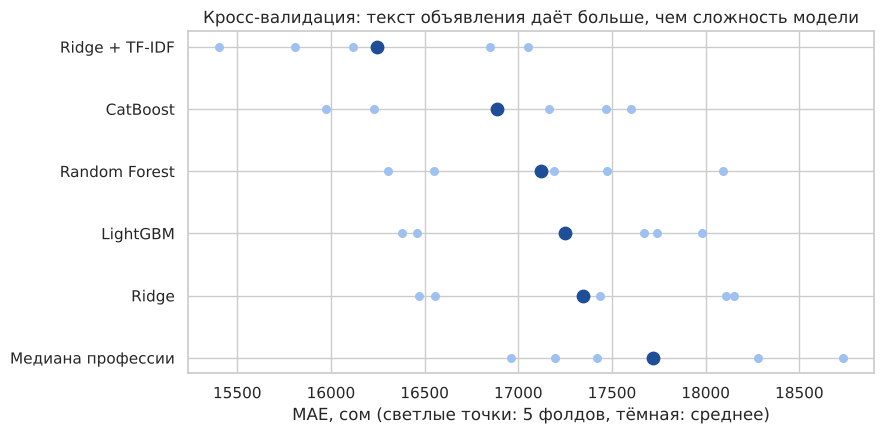

In [4]:
order = cv_sum.index[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, name in enumerate(order):
    v = cv.loc[cv["модель"] == name, "MAE, сом"]
    ax.scatter(v, [i] * len(v), color="#9ec1f0", s=30, zorder=2)
    ax.scatter(v.mean(), i, color="#1f4e99", s=80, zorder=3)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel("MAE, сом (светлые точки: 5 фолдов, тёмная: среднее)")
ax.set_title("Кросс-валидация: текст объявления даёт больше, чем сложность модели")
plt.tight_layout(); plt.savefig(FIG + "02_cv.png", dpi=150); plt.show()

## 2. Проверка на тестовой выборке

Все модели обучаются на всей обучающей выборке и проверяются на тесте. Сюда добавлен
**CatBoost + текст**: он обучается дольше (около минуты), поэтому в кросс-валидацию не включён.

In [5]:
test_rows, preds = [], {}
all_models = {**MODELS, "CatBoost + текст": lambda: CB(text=True, iterations=800)}
for name, make in all_models.items():
    t0 = time.time()
    m = make().fit(train)
    preds[name] = m.predict(test)
    test_rows.append({"модель": name, **prep.metrics(test.y.values, preds[name]),
                      "время, с": time.time() - t0})
    if name == "Ridge + TF-IDF":
        best_model = m
res = pd.DataFrame(test_rows).set_index("модель").sort_values("MAE, сом")
res.style.format({"MAE, сом": "{:,.0f}", "медианная ошибка, сом": "{:,.0f}", "MAPE, %": "{:.1f}",
                  "доля ошибок < 20%": "{:.0%}", "R² (log)": "{:.3f}", "время, с": "{:.1f}"})

,"MAE, сом","медианная ошибка, сом","MAPE, %",доля ошибок < 20%,R² (log),"время, с"
модель,,,,,,
Ridge + TF-IDF,"16,249","9,780",35.4,41%,0.357,0.4
CatBoost + текст,"16,556","10,017",35.0,40%,0.329,65.1
CatBoost,"17,112","10,076",36.8,38%,0.291,5.0
Ridge,"17,512","10,561",38.1,38%,0.258,0.0
LightGBM,"17,544","10,625",37.6,37%,0.264,0.4
Медиана профессии,"17,793","10,000",38.0,38%,0.213,0.0
Random Forest,"18,037","10,852",39.1,38%,0.225,7.3


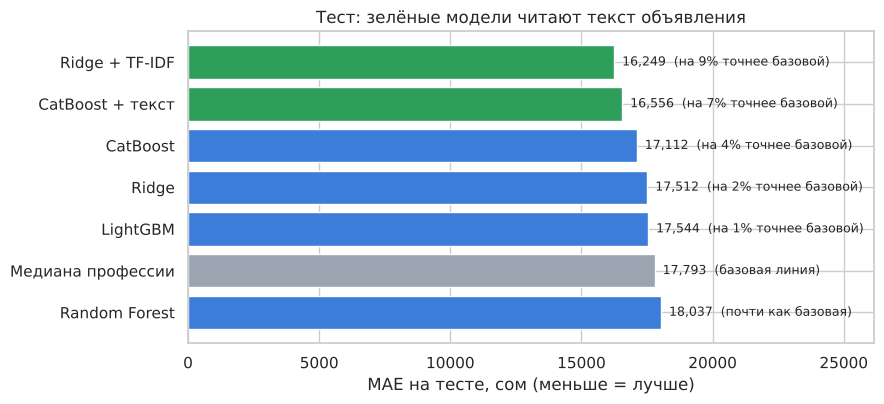

In [6]:
base = res.loc["Медиана профессии", "MAE, сом"]
gain = (1 - res["MAE, сом"] / base) * 100
fig, ax = plt.subplots(figsize=(9, 4.2))
cols = ["#2e9e5b" if ("TF-IDF" in n or "текст" in n) else ("#9aa5b1" if n == "Медиана профессии" else "#3b7dd8")
        for n in res.index]
ax.barh(res.index[::-1], res["MAE, сом"][::-1], color=cols[::-1])
for i, (v, g) in enumerate(zip(res["MAE, сом"][::-1], gain[::-1])):
    ax.text(v, i, f"  {v:,.0f}" + (f"  (на {g:.0f}% точнее базовой)" if g >= 0.5 else "  (базовая линия)" if g == 0 else "  (почти как базовая)"), va="center", fontsize=9)
ax.set_xlim(0, res["MAE, сом"].max() * 1.45)
ax.set_xlabel("MAE на тесте, сом (меньше = лучше)")
ax.set_title("Тест: зелёные модели читают текст объявления")
plt.tight_layout(); plt.savefig(FIG + "02_test.png", dpi=150); plt.show()

## 3. Сохранение лучшей модели

Лучшая по тесту и кросс-валидации модель сохраняется в `models/` для следующих шагов
(подбор гиперпараметров, анализ ошибок, приложение).

In [7]:
joblib.dump(best_model.model, "../models/ridge_tfidf.joblib")   # чистый sklearn-пайплайн: загружается где угодно
print("Сохранено: models/ridge_tfidf.joblib")

Сохранено: models/ridge_tfidf.joblib


## Выводы

| Модель | MAE, кросс-валидация | MAE, тест | R² (log), тест |
|---|---|---|---|
| Медиана профессии | 17 718 ± 754 | 17 793 | 0,21 |
| Ridge | 17 344 ± 811 | 17 512 | 0,26 |
| LightGBM | 17 247 ± 764 | 17 544 | 0,26 |
| Random Forest | 17 122 ± 718 | 18 037 | 0,23 |
| CatBoost | 16 888 ± 739 | 17 112 | 0,29 |
| CatBoost + текст | не считалась | ≈ 16 550 | 0,33 |
| **Ridge + TF-IDF** | **16 246 ± 695** | **16 249** | **0,36** |

1. **Текст объявления даёт главный прирост.** Ridge + TF-IDF ошибается примерно на 9% меньше медианы
   профессии и в кросс-валидации, и на тесте, а R² (log) растёт с 0,21 до 0,36.
   Из текста предварительно удалены числа и названия валют, поэтому модель не может «прочитать»
   зарплату прямо из объявления.
2. **Сложная модель без новых признаков почти не помогает.** Random Forest, LightGBM и CatBoost
   на структурированных признаках выигрывают у медианы профессии 1–5% в кросс-валидации, а Random Forest
   на тесте даже немного хуже её. Разница между ними меньше разброса по фолдам.
3. **Лучшая модель на текущем этапе: Ridge + TF-IDF.** Она точнее, обучается меньше секунды
   (CatBoost + текст около минуты) и проще в объяснении: у каждого слова есть свой вес.
4. **Кросс-валидация и тест согласуются:** у лучшей модели ошибка почти одинаковая (16 246 и 16 249),
   порядок моделей похожий, поэтому выбор устойчив.
5. **Задача шумная.** Даже лучшая модель ошибается в среднем на 35% (MAPE); половина ошибок меньше
   ~9 800 сом. Причины видны из анализа: зарплаты округлены до 5–10 тыс. (H3), часть сумм это
   пересчитанные дневные ставки, а одна профессия может стоить от 30 до 100+ тыс. сом.

**Следующие шаги:**
- подбор гиперпараметров (Optuna) для Ridge + TF-IDF и CatBoost + текст;
- признаки из текста: навыки, уровень должности (старший, руководитель), условия;
- анализ ошибок: на каких профессиях и диапазонах модель ошибается сильнее всего;
- применение к 6 516 вакансиям со скрытой зарплатой.